# 03 · Model development and evaluation

Every model is trained on the **training** part, compared on the **validation** part, and only the best three are scored on the **test** part, once, at the end.

Order of work:
1. Shared helpers: one threshold rule and one evaluation function used by every model
2. Baseline "always normal"
3. PCA reconstruction-error detector (learns normal blocks only)
4. Logistic regression, with and without class weights
5. Decision tree: depth sweep for bias-variance, then readable rules
6. kNN, choosing k on validation
7. Gaussian Naive Bayes
8. Linear SVM
9. Random forest
10. AdaBoost
11. Small MLP
12. Validation comparison → test the top three once → save the best model

**It creates** `reports/tables/model_comparison.csv`, `final_test_results.csv`, `model_settings.csv`, `event_importance.csv`, `decision_tree_rules.txt`, `models/best_final_model.pkl` and the figures `tree_depth_bias_variance.png`, `decision_tree.png`, `validation_precision_recall.png`, `test_roc_curves.png`.

In [1]:
from pathlib import Path
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

root = Path.cwd()
if not (root / 'datasets').exists():
    root = root.parent
processed = root / 'datasets' / 'processed'
figures = root / 'reports' / 'figures'
tables = root / 'reports' / 'tables'
models_folder = root / 'models'
models_folder.mkdir(exist_ok=True)

NORMAL_COLOUR = '#8a8a8a'
ANOMALY_COLOUR = '#d4591c'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.9.1


In [2]:
df = pd.read_csv(processed / 'hdfs_clean.csv')
splits = np.load(processed / 'splits.npz')
event_columns = [name for name in df.columns if name.startswith('E') and name[1:].isdigit()]

X = df[event_columns].values
y = df['target'].values
X_train, y_train = X[splits['train_idx']], y[splits['train_idx']]
X_val, y_val = X[splits['validation_idx']], y[splits['validation_idx']]
X_test, y_test = X[splits['test_idx']], y[splits['test_idx']]

for part_name, part_y in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{part_name:10s} blocks {len(part_y):7d}   anomalies {part_y.sum():6d}   rate {part_y.mean():.6f}')

train      blocks  345036   anomalies  10103   rate 0.029281
validation blocks  115012   anomalies   3367   rate 0.029275
test       blocks  115013   anomalies   3368   rate 0.029284


## 1 · The alarm threshold rule

Each model gives every block a **score**: higher means more suspicious. An alarm is raised when `score >= threshold`.

The threshold is chosen on the **validation** set by minimising

> cost = 10 × false negatives + 1 × false positives

because missing a broken block is assumed to be ten times worse than a false alarm.

**Which thresholds are tried?**
- every distinct score the model produced on validation. A threshold between two neighbouring scores flags exactly the same blocks as the higher one, so this list contains every decision the model can make;
- an even 201-point grid across the score range, so values in the gaps are tried too;
- infinity, meaning "never raise an alarm".

When several thresholds give the same lowest cost they flag the same validation blocks; the lowest one is kept so that, on new data, the model leans towards raising an alarm (a miss costs ten times more).

**Fix for the earlier version.** The old results chose thresholds with `score >= t` but computed the metrics with `score > t`. Naive Bayes and kNN give many blocks a score of exactly 1.0, so their chosen threshold of 1.0 flagged thousands of blocks during selection and none during evaluation: zero true positives despite an AUC near 0.998.
Now one function, `predict_at`, is used for both choosing and evaluating, so the two can never disagree.

In [3]:
FN_COST = 10  # cost of a missed anomaly (false negative)
FP_COST = 1   # cost of a false alarm (false positive)


def predict_at(scores, threshold):
    # The only place where scores become decisions: 1 = raise an alarm.
    return (scores >= threshold).astype(int)


def choose_threshold(y_true, scores):
    distinct_scores = np.unique(scores)
    grid = np.linspace(scores.min(), scores.max(), 201)
    candidates = np.unique(np.concatenate([distinct_scores, grid, [np.inf]]))

    costs = []
    for threshold in candidates:
        predicted = predict_at(scores, threshold)
        false_negatives = np.sum((predicted == 0) & (y_true == 1))
        false_positives = np.sum((predicted == 1) & (y_true == 0))
        costs.append(FN_COST * false_negatives + FP_COST * false_positives)

    # Candidates are sorted, and argmin returns the first minimum, so ties go to the lowest threshold.
    best = int(np.argmin(costs))
    return candidates[best], costs[best]

## Evaluation helpers

`evaluate` turns scores and a threshold into every metric on the syllabus. AUC uses the raw scores (it measures ranking, so it needs no threshold).
Log loss is only defined for scores that are probabilities; for the PCA detector and the SVM it is left empty.

`record` runs a fitted model on the validation set, chooses its threshold, prints the metrics and confusion matrix, and stores the model, its scores and its settings for later.

In [4]:
def evaluate(y_true, scores, threshold, gives_probability):
    predicted = predict_at(scores, threshold)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    row = {
        'threshold': threshold,
        'accuracy': accuracy_score(y_true, predicted),
        'precision': precision_score(y_true, predicted, zero_division=0),
        'recall': recall_score(y_true, predicted),
        'f1': f1_score(y_true, predicted, zero_division=0),
        'auc': roc_auc_score(y_true, scores),
        'log_loss': np.nan,
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
        'cost': FN_COST * fn + FP_COST * fp,
    }
    if gives_probability:
        row['log_loss'] = log_loss(y_true, scores, labels=[0, 1])
    return row


def show(row):
    print(f"threshold {row['threshold']:.6g}   cost {row['cost']}")
    print(f"accuracy {row['accuracy']:.6f}   precision {row['precision']:.6f}   recall {row['recall']:.6f}")
    print(f"F1 {row['f1']:.6f}   AUC {row['auc']:.6f}   log loss {row['log_loss']:.6f}")
    matrix = pd.DataFrame([[row['tn'], row['fp']], [row['fn'], row['tp']]],
                          index=['actual normal', 'actual anomaly'],
                          columns=['predicted normal', 'predicted anomaly'])
    display(matrix)

In [5]:
results = []            # one row of validation metrics per model
settings = []           # one row of hyperparameters per model
fitted = {}             # model name -> (model, score function, gives probability)
validation_scores = {}  # model name -> validation scores, reused for plots


def record(name, model, score_function, gives_probability, setting_text, training_rows):
    scores = score_function(model, X_val)
    threshold, cost = choose_threshold(y_val, scores)
    row = evaluate(y_val, scores, threshold, gives_probability)
    row['model'] = name
    results.append(row)
    settings.append({'model': name, 'settings': setting_text, 'training_rows': training_rows,
                     'scikit_learn_version': sklearn.__version__})
    fitted[name] = (model, score_function, gives_probability)
    validation_scores[name] = scores
    show(row)

Three kinds of score are used: a predicted probability of anomaly, the signed distance from the SVM boundary, and the PCA reconstruction error.

In [6]:
def anomaly_probability(model, X_part):
    return model.predict_proba(X_part)[:, 1]


def svm_margin(model, X_part):
    return model.decision_function(X_part)


def reconstruction_error(model, X_part):
    # Project onto the normal-behaviour components and back; what is lost is the error.
    scaled = model.named_steps['standardscaler'].transform(X_part)
    pca = model.named_steps['pca']
    rebuilt = pca.inverse_transform(pca.transform(scaled))
    return ((scaled - rebuilt) ** 2).sum(axis=1)

## 2 · Baseline: always "normal"

`DummyClassifier(strategy='prior')` gives every block the same score: the training anomaly rate. With one score for everyone, the cheapest threshold is "never alarm". This is the number every real model must beat: high accuracy, zero recall.

In [7]:
baseline = DummyClassifier(strategy='prior')
baseline.fit(X_train, y_train)
record('Baseline (always normal)', baseline, anomaly_probability, True,
       "DummyClassifier(strategy='prior')", len(y_train))

threshold inf   cost 33670
accuracy 0.970725   precision 0.000000   recall 0.000000
F1 0.000000   AUC 0.500000   log loss 0.132214


,predicted normal,predicted anomaly
actual normal,111645,0
actual anomaly,3367,0


## 3 · PCA reconstruction-error detector

This detector never sees an anomaly while learning. It is fitted on **normal training blocks only**:
1. standardise the counts;
2. keep the PCA components that explain 95% of the variance of normal blocks;
3. score a block by how badly those components rebuild it (sum of squared errors).

A normal-looking block is rebuilt well; an unusual one is not. The labels are used only to choose the alarm threshold on validation.

In [8]:
normal_train = X_train[y_train == 0]
pca_detector = make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=42))
pca_detector.fit(normal_train)
print('components kept:', pca_detector.named_steps['pca'].n_components_)

record('PCA anomaly detector', pca_detector, reconstruction_error, False,
       'StandardScaler -> PCA(n_components=0.95, random_state=42); fitted on normal training blocks only; '
       'score = squared reconstruction error', len(normal_train))

components kept: 7


threshold 2.29944   cost 11067
accuracy 0.980228   precision 0.648223   recall 0.709831
F1 0.677630   AUC 0.957595   log loss nan


,predicted normal,predicted anomaly
actual normal,110348,1297
actual anomaly,977,2390


## 4 · Logistic regression

Counts are standardised so the solver converges and coefficients are comparable.
The first model uses the default equal class weights. The second uses `class_weight='balanced'`, which makes each anomaly count roughly as much as all the normal blocks together during fitting.
Because the threshold is tuned afterwards, both can end up at similar decisions; the weighting mostly moves the scores.

In [9]:
logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
logistic.fit(X_train, y_train)
record('Logistic regression', logistic, anomaly_probability, True,
       'StandardScaler -> LogisticRegression(max_iter=1000, random_state=42)', len(y_train))

threshold 0.11   cost 134
accuracy 0.999304   precision 0.978457   recall 0.998218
F1 0.988239   AUC 0.998997   log loss 0.002905


,predicted normal,predicted anomaly
actual normal,111571,74
actual anomaly,6,3361


In [10]:
logistic_balanced = make_pipeline(
    StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
logistic_balanced.fit(X_train, y_train)
record('Logistic regression balanced', logistic_balanced, anomaly_probability, True,
       "StandardScaler -> LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)",
       len(y_train))

threshold 0.885   cost 129
accuracy 0.999270   precision 0.977042   recall 0.998515
F1 0.987662   AUC 0.999653   log loss 0.008185


,predicted normal,predicted anomaly
actual normal,111566,79
actual anomaly,5,3362


## 5 · Decision tree and bias-variance

A shallow tree is too simple (high bias: low F1 on both training and validation). A very deep tree memorises the training blocks (high variance: training F1 keeps rising while validation F1 stops improving or falls).
The sweep fits trees of depth 1 to 20 and compares training and validation F1 at the default 0.5 cut. Trees do not need scaled inputs.

In [11]:
sweep = []
for depth in range(1, 21):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    sweep.append({'depth': depth,
                  'train_f1': f1_score(y_train, tree.predict(X_train)),
                  'validation_f1': f1_score(y_val, tree.predict(X_val))})
sweep = pd.DataFrame(sweep)
display(sweep)

,depth,train_f1,validation_f1
0,1,0.541925,0.539579
1,2,0.804139,0.791873
2,3,0.905060,0.902284
3,4,0.978960,0.977718
4,5,0.994166,0.994362
5,6,0.995650,0.995249
6,7,0.996345,0.995548
7,8,0.996789,0.996145
8,9,0.997281,0.996439
9,10,0.997925,0.997034


In [12]:
sweep.to_csv(tables / 'tree_depth_sweep.csv', index=False)

depth with the highest validation F1: 12


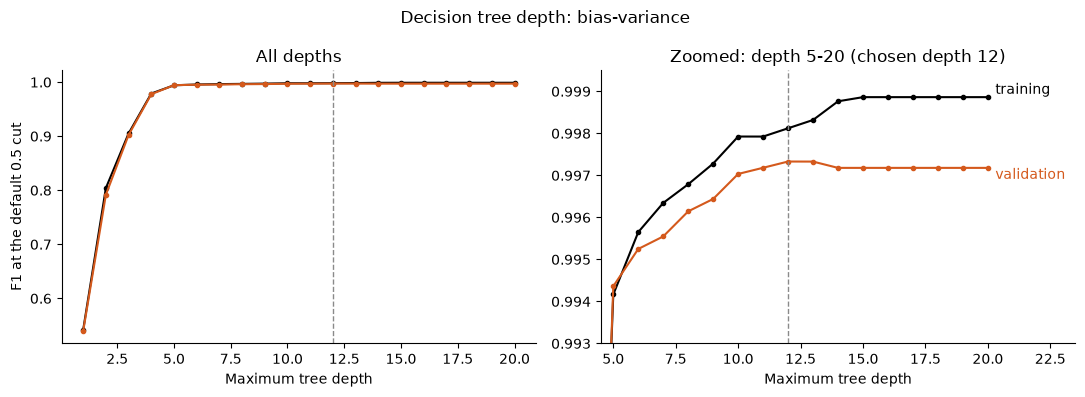

In [13]:
# idxmax returns the first maximum, so among equal scores the shallowest tree wins.
best_depth = int(sweep.loc[sweep['validation_f1'].idxmax(), 'depth'])
print('depth with the highest validation F1:', best_depth)

# Left: the whole sweep. Right: the same lines zoomed in, where the train-validation gap is visible.
fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(11, 4))
for ax in (ax_full, ax_zoom):
    ax.plot(sweep['depth'], sweep['train_f1'], color='black', marker='o', markersize=3)
    ax.plot(sweep['depth'], sweep['validation_f1'], color=ANOMALY_COLOUR, marker='o', markersize=3)
    ax.axvline(best_depth, color=NORMAL_COLOUR, linestyle='--', linewidth=1)
    ax.set_xlabel('Maximum tree depth')
ax_full.set_ylabel('F1 at the default 0.5 cut')
ax_full.set_title('All depths')
ax_zoom.set_xlim(4.5, 23.5)
ax_zoom.set_ylim(0.993, 0.9995)
ax_zoom.set_title(f'Zoomed: depth 5-20 (chosen depth {best_depth})')
last = sweep.iloc[-1]
ax_zoom.text(last['depth'] + 0.3, last['train_f1'], 'training', va='bottom')
ax_zoom.text(last['depth'] + 0.3, last['validation_f1'], 'validation', va='top', color=ANOMALY_COLOUR)
fig.suptitle('Decision tree depth: bias-variance')
fig.tight_layout()
fig.savefig(figures / 'tree_depth_bias_variance.png', dpi=160)
plt.show()

In [14]:
decision_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
decision_tree.fit(X_train, y_train)
record('Decision tree', decision_tree, anomaly_probability, True,
       f'DecisionTreeClassifier(max_depth={best_depth}, random_state=42); depth chosen by validation F1 over 1-20',
       len(y_train))

threshold 0.03   cost 63
accuracy 0.999843   precision 0.996148   recall 0.998515
F1 0.997330   AUC 0.999545   log loss 0.001780


,predicted normal,predicted anomaly
actual normal,111632,13
actual anomaly,5,3362


### Readable rules

The chosen tree is too deep to read, so a separate **depth-3 tree** is fitted only to explain the main splits.
`export_text` prints each rule; `weights` are the numbers of training blocks [normal, anomaly] that reach each leaf. Counts are whole numbers, so `E11 <= 2.50` means "E11 happened at most 2 times".

In [15]:
rules_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
rules_tree.fit(X_train, y_train)
rules = export_text(rules_tree, feature_names=event_columns, show_weights=True)
print(rules)
(tables / 'decision_tree_rules.txt').write_text(rules)
print('depth-3 tree validation F1 at the 0.5 cut:', round(f1_score(y_val, rules_tree.predict(X_val)), 6))

|--- E9 <= 2.50
|   |--- weights: [0.00, 3755.00] class: 1
|--- E9 >  2.50
|   |--- E20 <= 0.50
|   |   |--- E26 <= 3.50
|   |   |   |--- weights: [333705.00, 812.00] class: 0
|   |   |--- E26 >  3.50
|   |   |   |--- weights: [1104.00, 2414.00] class: 1
|   |--- E20 >  0.50
|   |   |--- E3 <= 7.50
|   |   |   |--- weights: [3.00, 3097.00] class: 1
|   |   |--- E3 >  7.50
|   |   |   |--- weights: [121.00, 25.00] class: 0

depth-3 tree validation F1 at the 0.5 cut: 0.902284


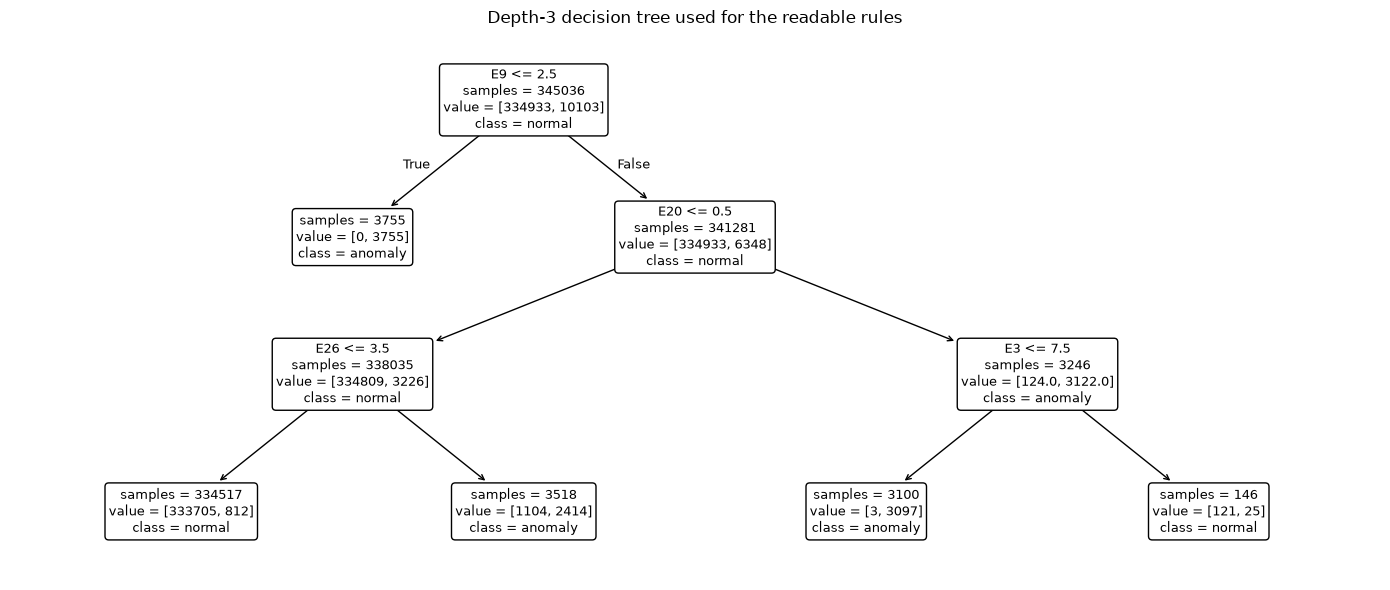

In [16]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(rules_tree, feature_names=event_columns, class_names=['normal', 'anomaly'],
          impurity=False, proportion=False, rounded=True, fontsize=9, ax=ax)
ax.set_title('Depth-3 decision tree used for the readable rules')
fig.tight_layout()
fig.savefig(figures / 'decision_tree.png', dpi=160)
plt.show()

## 6 · k-nearest neighbours

kNN measures distance, so counts are standardised first; otherwise a large count like `E3` would swamp everything else.
The full training part is used (no sample): scoring the validation set takes well under a minute per k.

The kNN score is the share of the k nearest training blocks that are anomalies, so it can only take k + 1 values (0, 1/k, …, 1). **A larger k gives more possible distinct score values**, which gives the threshold more room; the `distinct_scores` column shows how many actually occur on validation. k = 5, 15 and 25 are compared with the same cost rule, and the cheapest k is kept.

In [17]:
knn_rows = []
knn_models = {}
for k in [5, 15, 25]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    knn.fit(X_train, y_train)
    scores = anomaly_probability(knn, X_val)
    threshold, cost = choose_threshold(y_val, scores)
    knn_rows.append({'k': k, 'distinct_scores': len(np.unique(scores)),
                     'threshold': threshold, 'validation_cost': cost})
    knn_models[k] = knn
knn_table = pd.DataFrame(knn_rows)
display(knn_table)

,k,distinct_scores,threshold,validation_cost
0,5,6,0.205,56
1,15,14,0.005,60
2,25,14,0.045,56


In [18]:
# idxmin returns the first minimum, so a tie goes to the smaller k.
best_k = int(knn_table.loc[knn_table['validation_cost'].idxmin(), 'k'])
print('chosen k:', best_k)
record('kNN', knn_models[best_k], anomaly_probability, True,
       f'StandardScaler -> KNeighborsClassifier(n_neighbors={best_k}); k chosen from 5, 15, 25 by validation cost; '
       'full training part, no sample', len(y_train))

chosen k: 5


threshold 0.205   cost 56
accuracy 0.999826   precision 0.995265   recall 0.998812
F1 0.997035   AUC 0.999361   log loss 0.004493


,predicted normal,predicted anomaly
actual normal,111629,16
actual anomaly,4,3363


## 7 · Gaussian Naive Bayes

Naive Bayes assumes the events are independent given the class. They are not (several events are near-perfect twins, see notebook 02), so the model counts the same evidence several times and its probabilities are pushed to the extremes: many blocks get exactly 1.0 and most others sit extremely close to 0.
Its ranking can still be good (high AUC); the threshold search over its own distinct scores finds a usable cut.

In [19]:
naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)
record('Naive Bayes', naive_bayes, anomaly_probability, True, 'GaussianNB() with default var_smoothing=1e-9',
       len(y_train))

threshold 1.31062e-09   cost 412
accuracy 0.996418   precision 0.890976   recall 1.000000
F1 0.942345   AUC 0.998153   log loss 0.129791


,predicted normal,predicted anomaly
actual normal,111233,412
actual anomaly,0,3367


In [20]:
nb_scores = validation_scores['Naive Bayes']
print('distinct validation scores:', len(np.unique(nb_scores)))
print('share of scores below 0.000001:', round(np.mean(nb_scores < 1e-6), 4))
print('share of scores exactly 1:', round(np.mean(nb_scores == 1), 4))

# The old bug, reproduced: the same cut of 1.0 with the two different comparisons.
print('blocks flagged by score >= 1.0:', np.sum(nb_scores >= 1.0))
print('blocks flagged by score >  1.0:', np.sum(nb_scores > 1.0))

distinct validation scores: 122
share of scores below 0.000001: 0.9672
share of scores exactly 1: 0.0328
blocks flagged by score >= 1.0: 3775
blocks flagged by score >  1.0: 0


## 8 · Linear SVM

`LinearSVC` finds a straight boundary between the classes. Its score is the signed distance from that boundary, not a probability, so log loss is left empty.
It is fast enough to use the full training part. `dual=False` is the recommended solver when there are many more blocks than features.

In [21]:
svm = make_pipeline(StandardScaler(), LinearSVC(dual=False, max_iter=5000, random_state=42))
svm.fit(X_train, y_train)
record('Linear SVM', svm, svm_margin, False,
       'StandardScaler -> LinearSVC(dual=False, max_iter=5000, random_state=42); score = decision_function',
       len(y_train))

threshold -0.699811   cost 125
accuracy 0.999304   precision 0.978179   recall 0.998515
F1 0.988242   AUC 0.998988   log loss nan


,predicted normal,predicted anomaly
actual normal,111570,75
actual anomaly,5,3362


## 9 · Random forest (bagging)

A random forest trains many deep trees, each on a bootstrap sample of the training blocks and a random subset of events at each split, then averages them. Averaging cuts the variance that a single deep tree has. Its score is the average anomaly probability over the 200 trees.

In [22]:
forest = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
forest.fit(X_train, y_train)
record('Random forest', forest, anomaly_probability, True,
       "RandomForestClassifier(n_estimators=200, max_features='sqrt' (default), max_depth=None (default), "
       'random_state=42, n_jobs=-1)', len(y_train))

threshold 0.135   cost 34
accuracy 0.999861   precision 0.995857   recall 0.999406
F1 0.997628   AUC 0.999998   log loss 0.000446


,predicted normal,predicted anomaly
actual normal,111631,14
actual anomaly,2,3365


In [23]:
importance = pd.DataFrame({'event': event_columns, 'importance': forest.feature_importances_})
importance = importance.sort_values('importance', ascending=False)
importance.to_csv(tables / 'event_importance.csv', index=False)
display(importance.head(10))

,event,importance
19,E20,0.275093
25,E26,0.132600
10,E11,0.102006
8,E9,0.095257
4,E5,0.079339
20,E21,0.068292
26,E27,0.054346
27,E28,0.040787
12,E13,0.026953
22,E23,0.024568


## 10 · AdaBoost (boosting)

AdaBoost trains decision stumps (one-split trees) one after another; each new stump focuses on the blocks the previous ones got wrong. Where the forest reduces variance by averaging, boosting reduces bias by adding.

In [24]:
adaboost = AdaBoostClassifier(n_estimators=200, random_state=42)
adaboost.fit(X_train, y_train)
record('AdaBoost', adaboost, anomaly_probability, True,
       'AdaBoostClassifier(n_estimators=200, estimator=depth-1 stump (default), learning_rate=1.0, random_state=42)',
       len(y_train))

threshold 0.483988   cost 225
accuracy 0.999217   precision 0.978115   recall 0.995545
F1 0.986753   AUC 0.999949   log loss 0.543443


,predicted normal,predicted anomaly
actual normal,111570,75
actual anomaly,15,3352


AdaBoost's `predict_proba` is not a calibrated probability: its scores stay close to 0.5, so its log loss is poor even when its ranking (AUC) is good. The range below shows this.

In [25]:
ada_scores = validation_scores['AdaBoost']
print('lowest AdaBoost score:', round(ada_scores.min(), 4), '  highest:', round(ada_scores.max(), 4))

lowest AdaBoost score: 0.4122   highest: 0.6994


## 11 · Small MLP

A neural network with two hidden layers of 32 and 16 units. Inputs are standardised. `early_stopping=True` holds back 10% of the training part and stops when its score stops improving, which guards against overfitting.

In [26]:
mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True,
                                                    max_iter=100, random_state=42))
mlp.fit(X_train, y_train)
print('training epochs run:', mlp.named_steps['mlpclassifier'].n_iter_)
record('MLP', mlp, anomaly_probability, True,
       'StandardScaler -> MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=100, '
       'random_state=42)', len(y_train))

training epochs run: 12


threshold 0.02   cost 104
accuracy 0.999331   precision 0.978476   recall 0.999109
F1 0.988685   AUC 0.999995   log loss 0.000994


,predicted normal,predicted anomaly
actual normal,111571,74
actual anomaly,3,3364


## 12 · Validation comparison

All models, sorted by validation cost (ties broken by F1). This table, and only this table, decides which models go to the test set.

In [27]:
columns = ['model', 'threshold', 'accuracy', 'precision', 'recall', 'f1', 'auc', 'log_loss',
           'tn', 'fp', 'fn', 'tp', 'validation_cost']
comparison = pd.DataFrame(results).rename(columns={'cost': 'validation_cost'})
comparison = comparison.sort_values(['validation_cost', 'f1'], ascending=[True, False])[columns]
comparison = comparison.reset_index(drop=True)
comparison.to_csv(tables / 'model_comparison.csv', index=False)
display(comparison)

,model,threshold,accuracy,precision,recall,f1,auc,log_loss,tn,fp,fn,tp,validation_cost
0,Random forest,1.350000e-01,0.999861,0.995857,0.999406,0.997628,0.999998,0.000446,111631,14,2,3365,34
1,kNN,2.050000e-01,0.999826,0.995265,0.998812,0.997035,0.999361,0.004493,111629,16,4,3363,56
2,Decision tree,3.000000e-02,0.999843,0.996148,0.998515,0.997330,0.999545,0.001780,111632,13,5,3362,63
3,MLP,2.000000e-02,0.999331,0.978476,0.999109,0.988685,0.999995,0.000994,111571,74,3,3364,104
4,Linear SVM,-6.998106e-01,0.999304,0.978179,0.998515,0.988242,0.998988,NaN,111570,75,5,3362,125
5,Logistic regression balanced,8.850000e-01,0.999270,0.977042,0.998515,0.987662,0.999653,0.008185,111566,79,5,3362,129
6,Logistic regression,1.100000e-01,0.999304,0.978457,0.998218,0.988239,0.998997,0.002905,111571,74,6,3361,134
7,AdaBoost,4.839883e-01,0.999217,0.978115,0.995545,0.986753,0.999949,0.543443,111570,75,15,3352,225
8,Naive Bayes,1.310623e-09,0.996418,0.890976,1.000000,0.942345,0.998153,0.129791,111233,412,0,3367,412
9,PCA anomaly detector,2.299444e+00,0.980228,0.648223,0.709831,0.677630,0.957595,NaN,110348,1297,977,2390,11067


In [28]:
# Save every model's validation scores, so the website can draw ROC and precision-recall
# curves for all models without training anything again.
score_names = list(validation_scores)
np.savez_compressed(processed / 'validation_scores.npz', model_names=np.array(score_names),
                    scores=np.vstack([validation_scores[name] for name in score_names]))
print('saved validation scores for', len(score_names), 'models')

saved validation scores for 11 models


In [29]:
model_settings = pd.DataFrame(settings)
model_settings.to_csv(tables / 'model_settings.csv', index=False)
pd.set_option('display.max_colwidth', None)
display(model_settings)

,model,settings,training_rows,scikit_learn_version
0,Baseline (always normal),DummyClassifier(strategy='prior'),345036,1.9.1
1,PCA anomaly detector,"StandardScaler -> PCA(n_components=0.95, random_state=42); fitted on normal training blocks only; score = squared reconstruction error",334933,1.9.1
2,Logistic regression,"StandardScaler -> LogisticRegression(max_iter=1000, random_state=42)",345036,1.9.1
3,Logistic regression balanced,"StandardScaler -> LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)",345036,1.9.1
4,Decision tree,"DecisionTreeClassifier(max_depth=12, random_state=42); depth chosen by validation F1 over 1-20",345036,1.9.1
5,kNN,"StandardScaler -> KNeighborsClassifier(n_neighbors=5); k chosen from 5, 15, 25 by validation cost; full training part, no sample",345036,1.9.1
6,Naive Bayes,GaussianNB() with default var_smoothing=1e-9,345036,1.9.1
7,Linear SVM,"StandardScaler -> LinearSVC(dual=False, max_iter=5000, random_state=42); score = decision_function",345036,1.9.1
8,Random forest,"RandomForestClassifier(n_estimators=200, max_features='sqrt' (default), max_depth=None (default), random_state=42, n_jobs=-1)",345036,1.9.1
9,AdaBoost,"AdaBoostClassifier(n_estimators=200, estimator=depth-1 stump (default), learning_rate=1.0, random_state=42)",345036,1.9.1


Precision against recall on validation for the three cheapest models. The dot marks each model's chosen threshold. The axes are zoomed because every curve sits in the top-right corner.

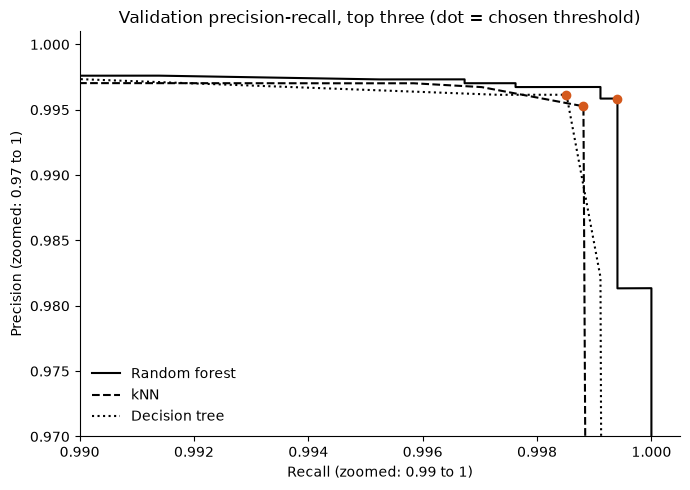

In [30]:
top_three = comparison['model'].head(3).tolist()
line_styles = ['-', '--', ':']

fig, ax = plt.subplots(figsize=(7, 5))
for name, style in zip(top_three, line_styles):
    precision, recall, _ = precision_recall_curve(y_val, validation_scores[name])
    ax.plot(recall, precision, color='black', linestyle=style, label=name)
    chosen = comparison.set_index('model').loc[name]
    ax.plot(chosen['recall'], chosen['precision'], 'o', color=ANOMALY_COLOUR)
ax.set_xlim(0.99, 1.0005)
ax.set_ylim(0.97, 1.001)
ax.set_xlabel('Recall (zoomed: 0.99 to 1)')
ax.set_ylabel('Precision (zoomed: 0.97 to 1)')
ax.set_title('Validation precision-recall, top three (dot = chosen threshold)')
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig(figures / 'validation_precision_recall.png', dpi=160)
plt.show()

## 13 · Test set, used once

The three cheapest validation models are scored on the test blocks with the thresholds chosen on validation. Nothing is re-tuned after this.

In [31]:
# Count how many times the test set is scored, for the leakage check below.
test_set_uses = 0

test_rows = []
test_scores = {}
test_set_uses += 1
for name in top_three:
    model, score_function, gives_probability = fitted[name]
    threshold = comparison.set_index('model').loc[name, 'threshold']
    test_scores[name] = score_function(model, X_test)
    row = evaluate(y_test, test_scores[name], threshold, gives_probability)
    row['model'] = name
    test_rows.append(row)
    print(name)
    show(row)

Random forest
threshold 0.135   cost 15
accuracy 0.999948   precision 0.998517   recall 0.999703
F1 0.999110   AUC 0.999995   log loss 0.000508


,predicted normal,predicted anomaly
actual normal,111640,5
actual anomaly,1,3367


kNN
threshold 0.205   cost 17
accuracy 0.999930   precision 0.997925   recall 0.999703
F1 0.998813   AUC 0.999838   log loss 0.001335


,predicted normal,predicted anomaly
actual normal,111638,7
actual anomaly,1,3367


Decision tree
threshold 0.03   cost 37
accuracy 0.999913   precision 0.997924   recall 0.999109
F1 0.998516   AUC 0.999553   log loss 0.001207


,predicted normal,predicted anomaly
actual normal,111638,7
actual anomaly,3,3365


In [32]:
final_columns = ['model', 'threshold', 'accuracy', 'precision', 'recall', 'f1', 'auc', 'log_loss',
                 'tn', 'fp', 'fn', 'tp', 'test_cost']
final = pd.DataFrame(test_rows).rename(columns={'cost': 'test_cost'})[final_columns]
final.to_csv(tables / 'final_test_results.csv', index=False)
display(final)

,model,threshold,accuracy,precision,recall,f1,auc,log_loss,tn,fp,fn,tp,test_cost
0,Random forest,0.135,0.999948,0.998517,0.999703,0.999110,0.999995,0.000508,111640,5,1,3367,15
1,kNN,0.205,0.999930,0.997925,0.999703,0.998813,0.999838,0.001335,111638,7,1,3367,17
2,Decision tree,0.030,0.999913,0.997924,0.999109,0.998516,0.999553,0.001207,111638,7,3,3365,37


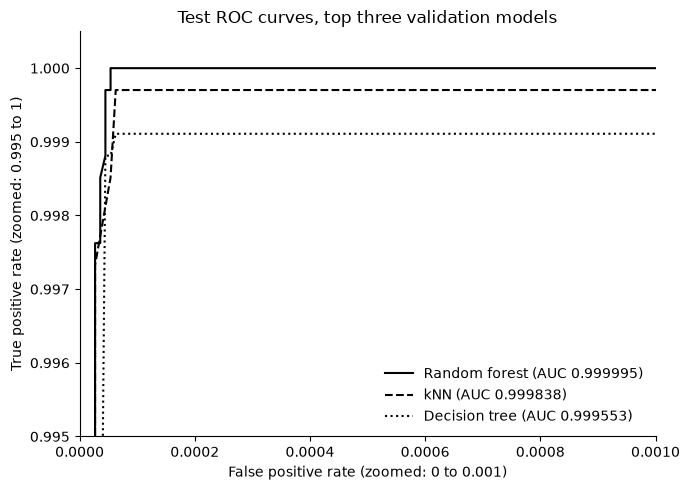

In [33]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, style in zip(top_three, line_styles):
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, test_scores[name])
    auc = final.set_index('model').loc[name, 'auc']
    ax.plot(false_positive_rate, true_positive_rate, color='black', linestyle=style,
            label=f'{name} (AUC {auc:.6f})')
ax.set_xlim(0, 0.001)
ax.set_ylim(0.995, 1.0005)
ax.set_xlabel('False positive rate (zoomed: 0 to 0.001)')
ax.set_ylabel('True positive rate (zoomed: 0.995 to 1)')
ax.set_title('Test ROC curves, top three validation models')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()
fig.savefig(figures / 'test_roc_curves.png', dpi=160)
plt.show()

## 14 · Leakage checks

Three things must hold for the test score to be honest:
1. the features are the 29 event counts only, with no id, label or `Type` column;
2. every scaler, the PCA and every model were fitted on training rows only (validation and test rows never reach `fit`);
3. the test set was scored once, after the models and thresholds were fixed.

Each fitted object remembers how many rows it saw. That number must equal the size of the training part (or of its normal blocks, for the PCA detector).

In [34]:
print('features used:', event_columns)
assert event_columns == [f'E{number}' for number in range(1, 30)]
for column in ['BlockId', 'Label', 'Type', 'target']:
    assert column not in event_columns
print('only E1-E29 are features: OK')

features used: ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26', 'E27', 'E28', 'E29']
only E1-E29 are features: OK


In [35]:
def training_rows_seen(model):
    # Each kind of model stores the number of rows it was fitted on in a different place.
    if hasattr(model, 'named_steps'):
        # A pipeline: the scaler is fitted first and counts every row passed to fit.
        return int(model.named_steps['standardscaler'].n_samples_seen_)
    if isinstance(model, RandomForestClassifier):
        # Bootstrap draws are stored as weights; they add up to the number of training rows.
        return int(model.estimators_[0].tree_.weighted_n_node_samples[0])
    if isinstance(model, AdaBoostClassifier):
        return int(model.estimators_[0].tree_.n_node_samples[0])
    if isinstance(model, DecisionTreeClassifier):
        return int(model.tree_.n_node_samples[0])
    if isinstance(model, GaussianNB):
        return int(model.class_count_.sum())
    return None

In [36]:
expected_rows = model_settings.set_index('model')['training_rows']
row_check = []
for name, (model, _, _) in fitted.items():
    if name == 'Baseline (always normal)':
        continue
    row_check.append({'model': name, 'rows_seen_in_fit': training_rows_seen(model),
                      'expected_training_rows': expected_rows[name]})
row_check = pd.DataFrame(row_check)
row_check['match'] = row_check['rows_seen_in_fit'] == row_check['expected_training_rows']
display(row_check)
assert row_check['match'].all()

,model,rows_seen_in_fit,expected_training_rows,match
0,PCA anomaly detector,334933,334933,True
1,Logistic regression,345036,345036,True
2,Logistic regression balanced,345036,345036,True
3,Decision tree,345036,345036,True
4,kNN,345036,345036,True
5,Naive Bayes,345036,345036,True
6,Linear SVM,345036,345036,True
7,Random forest,345036,345036,True
8,AdaBoost,345036,345036,True
9,MLP,345036,345036,True


In [37]:
pca_rows = pca_detector.named_steps['pca'].n_samples_
print('PCA fitted on', pca_rows, 'rows; normal training blocks:', len(normal_train), '; match:', pca_rows == len(normal_train))
print('baseline score equals the training anomaly rate:', np.isclose(baseline.class_prior_[1], y_train.mean()))
print('training rows:', len(y_train), ' validation rows:', len(y_val), ' test rows:', len(y_test))
print('test rows shared with training or validation:',
      len(np.intersect1d(splits['test_idx'], np.concatenate([splits['train_idx'], splits['validation_idx']]))))
print('times the test set was scored:', test_set_uses)
assert pca_rows == len(normal_train) and test_set_uses == 1

PCA fitted on 334933 rows; normal training blocks: 334933 ; match: True
baseline score equals the training anomaly rate: True
training rows: 345036  validation rows: 115012  test rows: 115013
test rows shared with training or validation: 0
times the test set was scored: 1


## 15 · Save the chosen model

The model with the lowest **validation** cost is saved with its threshold, so the website and any later script use exactly the same decision rule. It was chosen before the test set was scored.

In [38]:
best_name = comparison.loc[0, 'model']
best_model, best_score_function, _ = fitted[best_name]
package = {
    'model_name': best_name,
    'model': best_model,
    'threshold': float(comparison.loc[0, 'threshold']),
    'event_columns': event_columns,
    'decision_rule': 'alarm when predict_proba(X)[:, 1] >= threshold',
    'scikit_learn_version': sklearn.__version__,
}
with open(models_folder / 'best_final_model.pkl', 'wb') as file:
    pickle.dump(package, file)
print('saved', best_name, 'with threshold', package['threshold'])

saved Random forest with threshold 0.135


## Conclusion and limitations

The printed tables above are the results; the cell below repeats the headline test numbers for the chosen model.

- The threshold rule (10 × misses + false alarms) is an assumption. A different cost ratio would move every threshold.
- This is one labelled benchmark from one Hadoop deployment. The same model or threshold may not carry over to another system.
- Event counts show patterns associated with known labels; they do not explain why a block failed.

In [39]:
chosen = final.set_index('model').loc[best_name]
print('chosen model:', best_name)
print('test precision', round(chosen['precision'], 6), ' recall', round(chosen['recall'], 6),
      ' F1', round(chosen['f1'], 6), ' AUC', round(chosen['auc'], 6))
print('test missed anomalies (FN):', int(chosen['fn']), '  false alarms (FP):', int(chosen['fp']),
      '  out of', len(y_test), 'test blocks')

chosen model: Random forest
test precision 0.998517  recall 0.999703  F1 0.99911  AUC 0.999995
test missed anomalies (FN): 1   false alarms (FP): 5   out of 115013 test blocks
